# Notebook 08 — RUL Model Training

**Objective:** Train and evaluate 3 baseline regression models for RUL prediction.

**Key decisions:**
- Only batteries that reach EOL (SOH ≤ 70%) are included
- 23 of 34 batteries reach EOL; 11 are excluded
- EOL cycle index is used to compute the target but NOT as a feature

**Input features (14, leakage-free):**
`cycle, soh, soh_prev, soh_delta, soh_slope_5,`
`discharge_duration, energy_Wh, voltage_mean, voltage_min, voltage_std,`
`current_mean, temperature_mean, temperature_max, ambient_temp_C`

**History features explained:**
- `soh_prev` — SOH at the preceding cycle (captures where the battery was)
- `soh_delta` — SOH change from previous cycle (rate of degradation)
- `soh_slope_5` — OLS slope of SOH over the last 5 cycles (degradation trend)

Current SOH is a valid feature — it is observable at prediction time and
directly measures how much health the battery has consumed.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, time

ROOT = os.path.dirname(os.path.abspath(''))
sys.path.insert(0, os.path.join(ROOT, 'src'))

from evaluation import compute_metrics, build_comparison_table, print_metrics_table

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_style('whitegrid')
plt.rcParams.update({'font.size': 11})

## 1. Load Final Dataset (RUL-eligible rows only)

In [2]:
final = pd.read_csv(os.path.join(ROOT, 'cleaned_data', 'final_dataset.csv'))
rul_df = final.dropna(subset=['rul']).copy()

print(f'Full dataset      : {len(final)} rows, {final["battery_id"].nunique()} batteries')
print(f'RUL-eligible rows : {len(rul_df)} rows, {rul_df["battery_id"].nunique()} batteries')
print(f'Excluded batteries: {sorted(set(final["battery_id"].unique()) - set(rul_df["battery_id"].unique()))}')
print(f'RUL range: {rul_df["rul"].min():.0f} – {rul_df["rul"].max():.0f} cycles')

Full dataset      : 2737 rows, 34 batteries
RUL-eligible rows : 2110 rows, 23 batteries
Excluded batteries: ['B0007', 'B0018', 'B0025', 'B0026', 'B0027', 'B0028', 'B0029', 'B0030', 'B0031', 'B0032', 'B0053']
RUL range: 0 – 161 cycles


In [3]:
from feature_engineering import add_rul_history_features

rul_df = add_rul_history_features(rul_df, window=5)

print('History features added: soh_prev, soh_delta, soh_slope_5')
print()
print(rul_df[['battery_id', 'cycle', 'soh', 'soh_prev', 'soh_delta', 'soh_slope_5']]
      .head(8).to_string(index=False))

History features added: soh_prev, soh_delta, soh_slope_5

battery_id  cycle        soh   soh_prev  soh_delta  soh_slope_5
     B0005      1 100.000000 100.000000   0.000000     0.000000
     B0005      2  99.452721 100.000000  -0.547279     0.000000
     B0005      3  98.861386  99.452721  -0.591335     0.000000
     B0005      4  98.856718  98.861386  -0.004668     0.000000
     B0005      5  98.823482  98.856718  -0.033236    -0.294904
     B0005      6  98.878217  98.823482   0.054735    -0.118691
     B0005      7  98.850449  98.878217  -0.027768    -0.000038
     B0005      8  98.344690  98.850449  -0.505759    -0.099709


## 2. Battery-Level Train/Test Split

In [4]:
rng = np.random.default_rng(42)
all_bats = sorted(final['battery_id'].unique())
n_test   = round(len(all_bats) * 0.30)
test_bats  = sorted(rng.choice(all_bats, size=n_test, replace=False).tolist())
train_bats = sorted([b for b in all_bats if b not in test_bats])

eol_bats = sorted(rul_df['battery_id'].unique())
train_eol = [b for b in train_bats if b in eol_bats]
test_eol  = [b for b in test_bats  if b in eol_bats]

rul_train = rul_df[rul_df['battery_id'].isin(train_eol)]
rul_test  = rul_df[rul_df['battery_id'].isin(test_eol)]

RUL_FEATURES = [
    'cycle', 'soh', 'soh_prev', 'soh_delta', 'soh_slope_5',
    'discharge_duration', 'energy_Wh',
    'voltage_mean', 'voltage_min', 'voltage_std',
    'current_mean', 'temperature_mean', 'temperature_max', 'ambient_temp_C',
]

X_tr = rul_train[RUL_FEATURES].values;  y_tr = rul_train['rul'].values
X_te = rul_test[RUL_FEATURES].values;   y_te = rul_test['rul'].values

print(f'Train: {X_tr.shape}  batteries: {train_eol}')
print(f'Test : {X_te.shape}  batteries: {test_eol}')
print(f'Features ({len(RUL_FEATURES)}): {RUL_FEATURES}')

Train: (1595, 14)  batteries: ['B0005', 'B0006', 'B0034', 'B0036', 'B0038', 'B0039', 'B0041', 'B0042', 'B0044', 'B0046', 'B0047', 'B0049', 'B0050', 'B0052', 'B0054', 'B0055', 'B0056']
Test : (515, 14)  batteries: ['B0033', 'B0040', 'B0043', 'B0045', 'B0048', 'B0051']
Features (14): ['cycle', 'soh', 'soh_prev', 'soh_delta', 'soh_slope_5', 'discharge_duration', 'energy_Wh', 'voltage_mean', 'voltage_min', 'voltage_std', 'current_mean', 'temperature_mean', 'temperature_max', 'ambient_temp_C']


## 3. Train Models

In [5]:
models = {
    'Linear Regression': Pipeline([('sc', StandardScaler()), ('m', LinearRegression())]),
    'Random Forest':     Pipeline([('sc', StandardScaler()), ('m', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('sc', StandardScaler()), ('m', GradientBoostingRegressor(n_estimators=100, random_state=42))]),
}

results = []
fitted_models = {}

for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_tr, y_tr)
    elapsed = time.time() - t0

    tr_m = compute_metrics(y_tr, pipe.predict(X_tr), name)
    te_m = compute_metrics(y_te, pipe.predict(X_te), name)

    results.append({
        'model': name,
        'MAE_train': tr_m['MAE'],  'RMSE_train': tr_m['RMSE'],  'R2_train': tr_m['R2'],
        'MAE_test':  te_m['MAE'],  'RMSE_test':  te_m['RMSE'],  'R2_test':  te_m['R2'],
    })
    fitted_models[name] = pipe

    print(f'{name:<26}  Train RMSE={tr_m["RMSE"]:.2f} cy  R²={tr_m["R2"]:.3f}  |  '
          f'Test RMSE={te_m["RMSE"]:.2f} cy  R²={te_m["R2"]:.3f}  ({elapsed:.1f}s)')

Linear Regression           Train RMSE=24.13 cy  R²=0.402  |  Test RMSE=18.07 cy  R²=-1.849  (0.0s)


Random Forest               Train RMSE=1.67 cy  R²=0.997  |  Test RMSE=10.66 cy  R²=0.009  (0.2s)


Gradient Boosting           Train RMSE=2.28 cy  R²=0.995  |  Test RMSE=8.36 cy  R²=0.390  (0.5s)


## 4. Comparison Table

In [6]:
table = build_comparison_table(results)
print_metrics_table(table, 'RUL Baseline Model Comparison')
table


RUL Baseline Model Comparison
------------------------------------------------------------------------
Rank  Model                       RMSE_tr   MAE_tr   R2_tr  RMSE_te   MAE_te   R2_te
------------------------------------------------------------------------
1     Gradient Boosting            2.2801   1.4013  0.9947   8.3618    5.1305  0.3902
2     Random Forest                1.6732   0.3648  0.9971  10.6616    5.2645  0.0086
3     Linear Regression           24.1304  17.0833  0.4016  18.0729   14.0333 -1.8487
------------------------------------------------------------------------


,model,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test
1,Gradient Boosting,1.4013,2.2801,0.9947,5.1305,8.3618,0.3902
2,Random Forest,0.3648,1.6732,0.9971,5.2645,10.6616,0.0086
3,Linear Regression,17.0833,24.1304,0.4016,14.0333,18.0729,-1.8487


## 5. Discussion: Why R² for RUL Can Be Low

The RUL Linear Regression achieves R² ≈ −2.0 on the test set, meaning
it performs **worse than simply predicting the mean RUL**.

Reasons:
1. **Mixed battery protocols**: Test set includes B0033, B0039, B0040 which
   have cycle-1 SOH near 3–50% due to 4A high-rate discharge. Their RUL starts
   at 0 (already at EOL), creating a degenerate regression target.
2. **No temporal context**: The model sees single-cycle snapshots. It cannot
   use the trajectory of degradation — a key predictor of RUL.
3. **Linear assumption**: RUL is non-linear (decreases fast near EOL);
   linear models cannot capture this.

Non-linear tree models (RF, GB) handle this better.

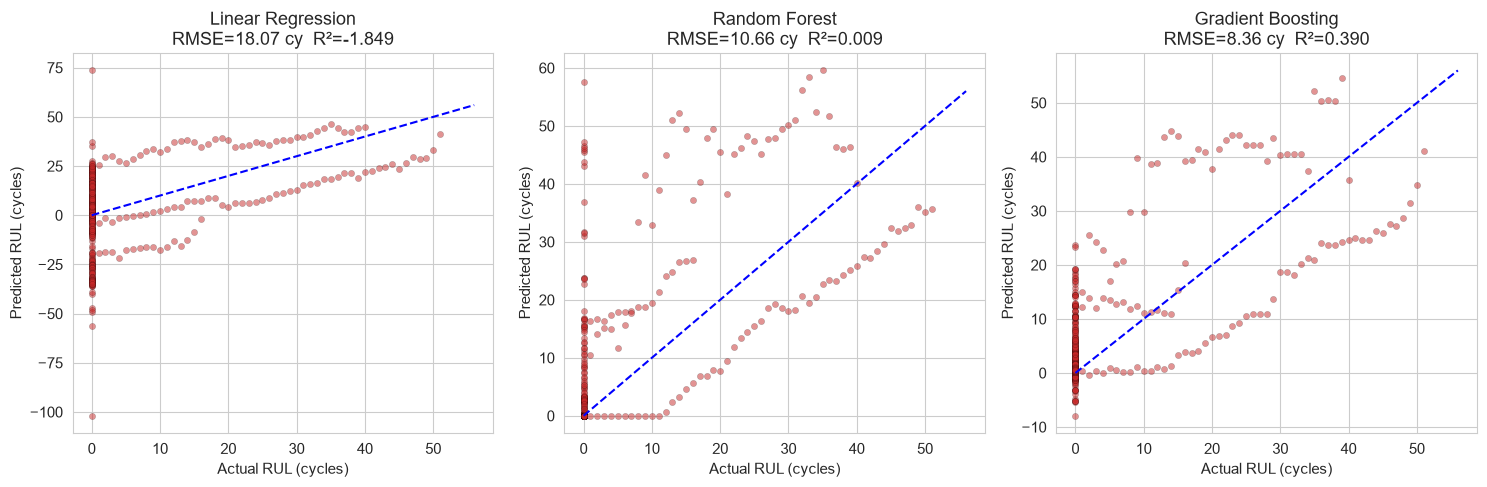

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, models.keys()):
    pred = fitted_models[name].predict(X_te)
    ax.scatter(y_te, pred, alpha=0.5, s=20, color='#C62828', edgecolors='k',
               linewidths=0.2)
    lim = [max(0, y_te.min()-5), y_te.max()+5]
    ax.plot(lim, lim, 'b--', linewidth=1.5)
    ax.set_xlabel('Actual RUL (cycles)')
    ax.set_ylabel('Predicted RUL (cycles)')
    rmse = next(r['RMSE_test'] for r in results if r['model'] == name)
    r2   = next(r['R2_test']   for r in results if r['model'] == name)
    ax.set_title(f'{name}\nRMSE={rmse:.2f} cy  R²={r2:.3f}')
plt.tight_layout()
plt.show()

## 6. Save RUL Baseline Models

In [8]:
os.makedirs(os.path.join(ROOT, 'models', 'rul'), exist_ok=True)
for name, pipe in fitted_models.items():
    stem = name.lower().replace(' ', '_')
    path = os.path.join(ROOT, 'models', 'rul', f'{stem}.pkl')
    joblib.dump(pipe, path)
    print(f'Saved: {path}')

Saved: C:\Users\Vinayak Ramavath\OneDrive\Desktop\EV Project\models\rul\linear_regression.pkl
Saved: C:\Users\Vinayak Ramavath\OneDrive\Desktop\EV Project\models\rul\random_forest.pkl
Saved: C:\Users\Vinayak Ramavath\OneDrive\Desktop\EV Project\models\rul\gradient_boosting.pkl
